# F6 · Breast: niches, block programmes and queries (Fig 6)

* **Needs:** `R6_breast_programs` (writes `results/breast_programs/`).
* **Writes:** `figures/fig6_breast/panels/{A..E}.{pdf,png}` and `figures/fig6_breast/fig6_breast.{pdf,png}`.

Panels A–C come from the whole-section build (`full`: every tile indexed), and D–E from seed 0, with E's summaries over seeds 0–4.
Niches are numbered from 1 (niche k of the build is "Niche k + 1").

| Panel | Content |
|---|---|
| A | Cells coloured by their tile's niche; log2 enrichment of the 19 annotated cell types per niche, and the section's fractions |
| B | r of ACTA2 with its block partners in each niche (○ = in ACTA2's block there) |
| C | Niche-mean correlation of the chosen niche (the most blocks both co-varying and enriched; ties go to more tiles), in its gene order with its blocks outlined; the largest other niche in the same order; the key of the co-varying blocks |
| D | The example whole-tile query (rule in `programs.py`) and Spindle-naive's top 10, cells by class; class compositions; TV of all held-out queries to the top 10 and to a random 10 |
| E | Gene-list queries, all five signatures (template query, mean ± s.d. over seeds): Cliff's δ of the top 10's score; co-variation on S against the typical tile |

In [1]:
import json
import re
import sys
from pathlib import Path

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "datasets.yaml").exists())
sys.path.insert(0, str(ROOT / "experiments" / "common"))
import numpy as np
import pandas as pd
from matplotlib.cm import ScalarMappable
from matplotlib.colors import Normalize
from matplotlib.lines import Line2D
from matplotlib.patches import Patch, Rectangle

import style as ps
from sections import CLASSES

FIG = "fig6_breast"
RES = ROOT / "results" / "breast_programs"
S0, FULL = RES / "seed0", RES / "full"
SEEDS = [0, 1, 2, 3, 4]
CLASS_COLORS = [c for _, c, _ in CLASSES]
SIG_LABELS = {"Luminal_Tumor_Core": "Luminal", "Macrophage_Myeloid": "Macrophage",
              "Basal_Myoepithelial": "Myoepithelial", "Endothelial_Vascular": "Endothelial",
              "Proliferation_Signature": "Proliferation"}
NO_TILE = "#E3E3E3"  # cells of the low-density tiles that tiling drops
NAIVE = ps.TIER_COLORS["naive"]
MAP_W = 60.0
CORR_LIM, ACTA2_LIM = 0.4, 0.6

blocks = pd.read_csv(FULL / "blocks.csv")
LAYOUT = json.loads((FULL / "layout.json").read_text())
GENES = np.array(LAYOUT["genes"])
NICHES = sorted(blocks.niche.unique())
NICHE_COLORS = ps.niche_palette(len(NICHES))
_b = blocks.assign(both=blocks.covarying & blocks.enriched).groupby("niche").agg(both=("both", "sum"),
                                                                                tiles=("n_tiles", "first"))
MAIN = int(_b.sort_values(["both", "tiles"], ascending=False).index[0])
CONTRAST = int(_b.drop(MAIN).sort_values("tiles", ascending=False).index[0])
print(f"chosen niche {MAIN + 1}, contrast niche {CONTRAST + 1}")


# ---- placement inside a panel (a Figure alone, a SubFigure from ps.place on the page): mm from its top-left corner
class At:
    def __init__(self, fig):
        self.fig, self.x0, self.y0 = fig, 0.0, 0.0
        self.W, self.H = ps.size_mm(fig)


def box(P, x, y, w, h, left=0.0, bottom=0.0, right=0.0, top=0.0, **kw):
    """Axes of the w x h mm box at (x, y) of the panel, inset by the margins (mm)."""
    x, y = P.x0 + x, P.y0 + y
    return P.fig.add_axes([(x + left) / P.W, 1 - (y + h - bottom) / P.H, (w - left - right) / P.W,
                           (h - top - bottom) / P.H], **kw)


def text(P, x, y, s, size=ps.LABEL_PT, ha="left", w=0.0, **kw):
    """Text with its top at y; ha="center" centres it on a w mm wide box at x."""
    x, y = P.x0 + x + (w / 2 if ha == "center" else 0), P.y0 + y
    P.fig.text(x / P.W, 1 - y / P.H, s, fontsize=size, ha=ha, va="top", **kw)


def hbar(P, x, y, w, h, cmap, vmin, vmax, ticks):
    """A horizontal colourbar as the old colorbar atoms (bar 2.5 mm, ticks below)."""
    ax = box(P, x, y, w, h, left=2.0, right=2.0, bottom=h - 3.0, top=0.5)
    cb = P.fig.colorbar(ScalarMappable(Normalize(vmin, vmax), cmap), cax=ax, orientation="horizontal", ticks=ticks)
    cb.outline.set_linewidth(0.5)


def legend(P, x, y, w, h, handles, ncol, **kw):
    x, y = P.x0 + x + w / 2, P.y0 + y + h / 2
    P.fig.legend(handles=handles, ncol=ncol, loc="center", bbox_to_anchor=(x / P.W, 1 - y / P.H), **kw)


def spatial(ax, x0, x1, y0, y1):
    ax.set_xlim(x0, x1)
    ax.set_ylim(y1, y0)  # image orientation
    ax.set_aspect("equal")
    ax.axis("off")


def heat_axes(ax):
    ax.tick_params(length=0)
    for s in ax.spines.values():
        s.set_visible(False)

chosen niche 1, contrast niche 2


## A · Niches and their cell types

figures/fig6_breast/panels/A.pdf/.png: 124 x 67 mm, 1.2 / 1.4 MB


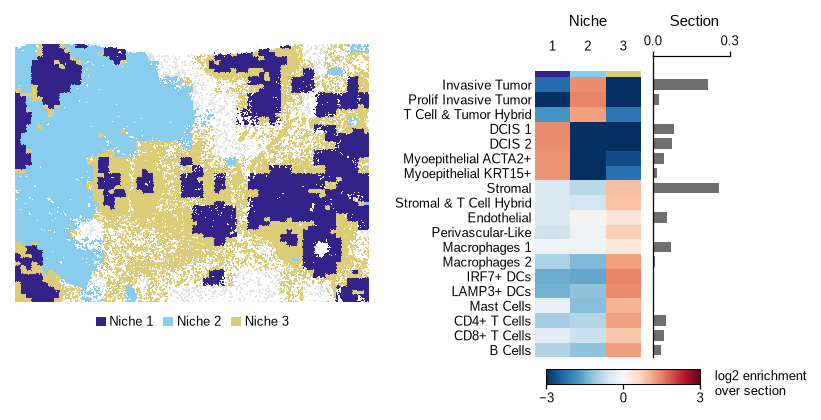

In [2]:
A_W, A_H = 124.0, 67.0


def panel_a(P):
    z = np.load(FULL / "cells_niche.npz")
    xy, niche = z["xy"], z["niche"]
    (x0, y0), (x1, y1) = xy.min(0), xy.max(0)
    ax = box(P, 0, 5, MAP_W, MAP_W * (y1 - y0) / (x1 - x0))
    col = np.array([NO_TILE] + NICHE_COLORS)[niche + 1]
    order = np.argsort(niche >= 0, kind="stable")  # cells without a tile underneath
    ax.scatter(xy[order, 0], xy[order, 1], s=0.05, c=col[order], lw=0, rasterized=True, antialiased=False)
    spatial(ax, x0, x1, y0, y1)
    legend(P, 0, 50, MAP_W, 4, [Patch(fc=c, ec="none", label=f"Niche {k + 1}") for k, c in zip(NICHES, NICHE_COLORS)],
           ncol=len(NICHES), handlelength=0.8, columnspacing=0.8, handletextpad=0.3)

    t = pd.read_csv(FULL / "niche_types.csv")
    types = [m for _, _, members in CLASSES for m in members]
    F = t.pivot(index="type", columns="niche", values="frac").loc[types, NICHES].to_numpy()
    sec = t.groupby("type")["section_frac"].first().loc[types].to_numpy()
    with np.errstate(divide="ignore"):
        E = np.clip(np.log2(F / sec[:, None]), -3, 3)
    ax = box(P, 62, 3, 62, 56, left=26.0, bottom=1.0, right=18.0, top=4.0)
    ax.imshow(E, cmap=ps.DIVERGING, vmin=-3, vmax=3, aspect="auto", interpolation="nearest")
    ax.set_yticks(range(len(types)))
    ax.set_yticklabels([s.replace("_", " ").replace("Myoepi ", "Myoepithelial ") for s in types])
    ax.set_xticks(range(len(NICHES)))
    ax.set_xticklabels([str(k + 1) for k in NICHES])
    ax.xaxis.tick_top()
    heat_axes(ax)
    for j, c in enumerate(NICHE_COLORS):
        ax.add_patch(Rectangle((j - 0.5, -0.5 - 0.45), 1, 0.4, fc=c, ec="none", clip_on=False))
    bx = box(P, 62 + 46, 3 + 4, 13, 51, sharey=ax)
    bx.barh(range(len(types)), sec, height=0.7, color=ps.MUTED, lw=0)
    bx.set_xlim(0, 0.3)
    bx.set_xticks([0, 0.3])
    bx.xaxis.tick_top()
    bx.tick_params(axis="y", left=False, labelleft=False)
    bx.spines["bottom"].set_visible(False)
    bx.spines["top"].set_visible(True)
    hbar(P, 88, 59.5, 30, 7, ps.DIVERGING, -3, 3, [-3, 0, 3])
    text(P, 88, 0, "Niche", ha="center", w=18)
    text(P, 108, 0, "Section", ha="center", w=14)
    text(P, 118.5, 60, "log2 enrichment\nover section", size=ps.TICK_PT)


fig = ps.panel(A_W, A_H)
panel_a(At(fig))
ps.save_panel(fig, FIG, "A")

## B · ACTA2's block partners per niche

figures/fig6_breast/panels/B.pdf/.png: 52 x 67 mm, 0.0 / 0.2 MB


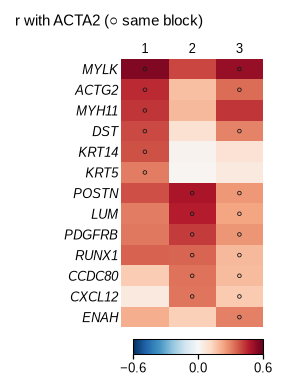

In [3]:
B_W, B_H = 52.0, 67.0


def panel_b(P):
    a = pd.read_csv(FULL / "acta2.csv")
    rows = []
    for k in NICHES:
        for g in a[(a.niche == k) & a.in_block].nlargest(6, "r").gene:
            if g not in rows:
                rows.append(g)
    r = a.pivot(index="gene", columns="niche", values="r").loc[rows, NICHES].to_numpy()
    inb = a.pivot(index="gene", columns="niche", values="in_block").loc[rows, NICHES].to_numpy().astype(bool)
    h = 3.0 + 3.5 * len(rows)
    ax = box(P, 10, 5, 38, h, left=13.0, bottom=0.5, right=1.0, top=2.5)
    ax.imshow(r, cmap=ps.DIVERGING, vmin=-ACTA2_LIM, vmax=ACTA2_LIM, aspect="auto", interpolation="nearest")
    yy, xx = np.nonzero(inb)
    ax.scatter(xx, yy, s=3, marker="o", fc="none", ec=ps.INK, lw=0.4)
    ax.set_yticks(range(len(rows)))
    ax.set_yticklabels(rows, fontstyle="italic")
    ax.set_xticks(range(len(NICHES)))
    ax.set_xticklabels([str(k + 1) for k in NICHES])
    ax.xaxis.tick_top()
    heat_axes(ax)
    hbar(P, 23, 5 + h + 1, 26, 7, ps.DIVERGING, -ACTA2_LIM, ACTA2_LIM, [-ACTA2_LIM, 0, ACTA2_LIM])
    text(P, 5, 0, "r with ACTA2 (○ same block)")


fig = ps.panel(B_W, B_H)
panel_b(At(fig))
ps.save_panel(fig, FIG, "B")

## C · Block programmes of the chosen niche, and the contrast niche in its order

figures/fig6_breast/panels/C.pdf/.png: 180 x 64 mm, 0.4 / 1.4 MB


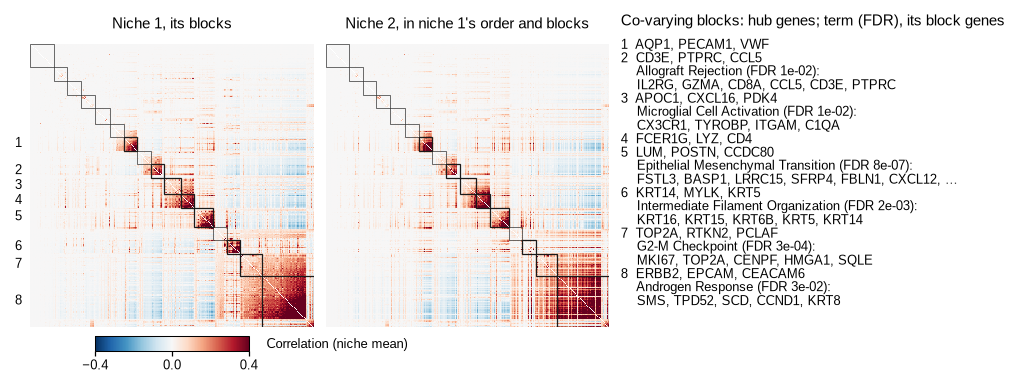

In [4]:
C_W, C_H = 180.0, 64.0
CX, CY, CW = 4.0, 7.0, 48.0  # main matrix: origin and side (mm)


def key_lines(main):
    lines = []
    for r in main.itertuples():
        if not r.covarying:
            continue
        line = f"{len(lines) + 1}  {', '.join(r.hubs.split())}"
        if r.enriched:
            term = re.sub(r"\s*\(GO:\d+\)", "", r.key_term)
            genes = r.key_genes.split()
            genes = ", ".join(genes[:6]) + (", …" if len(genes) > 6 else "")
            line += f"\n    {term} (FDR {r.key_fdr:.0e}):\n    {genes}"
        lines.append(line)
    return lines


def panel_c(P):
    perm = np.array(LAYOUT[str(MAIN)]["perm"])
    runs = LAYOUT[str(MAIN)]["blocks"]
    R_main = np.load(FULL / f"corr_niche{MAIN}.npy")
    R_c = np.load(FULL / f"corr_niche{CONTRAST}.npy")
    pos_c = np.empty(len(perm), int)
    pos_c[np.array(LAYOUT[str(CONTRAST)]["perm"])] = np.arange(len(perm))
    R_c = R_c[np.ix_(pos_c[perm], pos_c[perm])]  # contrast niche in the main niche's gene order
    main = blocks[blocks.niche == MAIN].sort_values("block")
    cov = main.set_index("block")
    for x, R in ((CX, R_main), (CX + CW + 2, R_c)):
        ax = box(P, x, CY, CW, CW)
        R = R.copy()
        np.fill_diagonal(R, np.nan)
        ax.imshow(R, cmap=ps.DIVERGING, vmin=-CORR_LIM, vmax=CORR_LIM, interpolation="nearest")
        for b, (s, e) in enumerate(runs):
            lw = 0.6 if cov.loc[b, "covarying"] else 0.3
            ax.add_patch(Rectangle((s - 0.5, s - 0.5), e - s, e - s, fill=False, ec=ps.INK, lw=lw))
        ax.set_xlim(-0.5, len(perm) - 0.5)
        ax.set_ylim(len(perm) - 0.5, -0.5)
        ax.axis("off")
    text(P, CX, CY - 4.5, f"Niche {MAIN + 1}, its blocks", ha="center", w=CW)
    text(P, CX + CW + 2, CY - 4.5, f"Niche {CONTRAST + 1}, in niche {MAIN + 1}'s order and blocks", ha="center", w=CW)
    hbar(P, 13, CY + CW + 1, 30, 7, ps.DIVERGING, -CORR_LIM, CORR_LIM, [-CORR_LIM, 0, CORR_LIM])
    text(P, 44, CY + CW + 1.8, "Correlation (niche mean)", size=ps.TICK_PT)
    p = len(GENES)
    num = 0
    for r in main.itertuples():
        if r.covarying:
            num += 1
            text(P, 0, CY + (r.start + r.end) / 2 / p * CW - 1.2, str(num), size=ps.TICK_PT, ha="center", w=4)
    text(P, 104, CY - 5, "Co-varying blocks: hub genes; term (FDR), its block genes")
    text(P, 104, CY - 1, "\n".join(key_lines(main)), size=ps.TICK_PT, linespacing=1.15)


fig = ps.panel(C_W, C_H)
panel_c(At(fig))
ps.save_panel(fig, FIG, "C")

## D · A whole-tile query, Spindle-naive's top 10, and all held-out queries

figures/fig6_breast/panels/D.pdf/.png: 119 x 46 mm, 0.2 / 0.9 MB


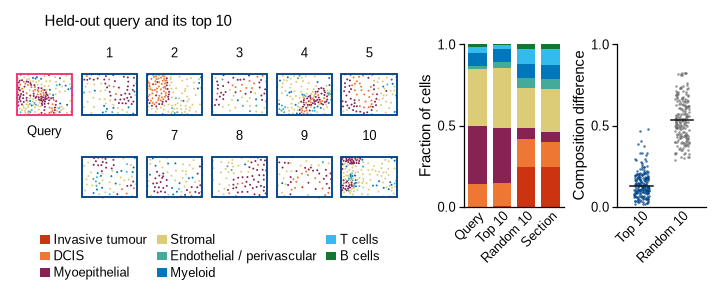

In [5]:
D_W, D_H = 119.0, 46.0
EY, ES = 9.0, 11.0  # example tiles: first row y, step (mm)


def panel_d(P):
    z = np.load(S0 / "example_cells.npz")
    for k in range(len(z["tiles"])):
        x = 0 if k == 0 else ES * (k if k <= 5 else k - 5)
        y = EY + (0 if k <= 5 else 14)
        x0, y0, x1, y1 = z[f"bbox{k}"]
        side = max(x1 - x0, y1 - y0) * 1.06
        cx, cy = (x0 + x1) / 2, (y0 + y1) / 2
        ax = box(P, x, y, 10, 10)
        ax.scatter(*z[f"xy{k}"].T, s=0.9, c=np.array(CLASS_COLORS)[z[f"cls{k}"]], lw=0, rasterized=True)
        ax.add_patch(Rectangle((x0, y0), x1 - x0, y1 - y0, fill=False, lw=0.9,
                               ec=ps.QUERY_COLOR if k == 0 else NAIVE))
        spatial(ax, cx - side / 2, cx + side / 2, cy - side / 2, cy + side / 2)
        text(P, x, y + 10.2 if k == 0 else y - 3.0, "Query" if k == 0 else str(k), size=ps.TICK_PT, ha="center", w=10)
    text(P, 5, 0.5, "Held-out query and its top 10")
    legend(P, 0, 37, 66, 9, [Patch(fc=c, ec="none", label=n) for n, c, _ in CLASSES], ncol=3,
           handlelength=0.8, columnspacing=0.8, handletextpad=0.3)

    ex = pd.read_csv(S0 / "example.csv").set_index("set")
    names = [n for n, _, _ in CLASSES]
    sets = [("query", "Query"), ("top10", "Top 10"), ("random10", "Random 10"), ("section", "Section")]
    ax = box(P, 68, 4, 26, 40, left=8.0, bottom=11.0, right=1.0, top=1.5)
    for i, (s, _) in enumerate(sets):
        bottom = 0.0
        for n, c in zip(names, CLASS_COLORS):
            v = ex.loc[s, n]
            ax.bar(i, v, 0.75, bottom=bottom, color=c, lw=0)
            bottom += v
    ax.set_xticks(range(len(sets)))
    ax.set_xticklabels([l for _, l in sets], rotation=45, ha="right", rotation_mode="anchor")
    ax.tick_params(axis="x", length=0)
    ax.set_ylim(0, 1)
    ax.set_yticks([0, 0.5, 1])
    ax.set_ylabel("Fraction of cells")

    q = pd.read_csv(S0 / "tile_queries.csv")
    ax = box(P, 94, 4, 24, 40, left=8.0, bottom=11.0, right=1.0, top=1.5)
    rng = np.random.default_rng(0)
    for i, (col, c) in enumerate((("tv_top", NAIVE), ("tv_random", ps.MUTED))):
        v = q[col].to_numpy()
        ax.scatter(i + rng.uniform(-0.18, 0.18, len(v)), v, s=1.5, c=c, lw=0, alpha=0.7, zorder=2)
        ax.plot([i - 0.28, i + 0.28], [np.median(v)] * 2, color=ps.INK, lw=0.75, zorder=3)
    ax.set_xticks([0, 1])
    ax.set_xticklabels(["Top 10", "Random 10"], rotation=45, ha="right", rotation_mode="anchor")
    ax.tick_params(axis="x", length=0)
    ax.set_xlim(-0.6, 1.6)
    ax.set_ylim(0, 1)
    ax.set_yticks([0, 0.5, 1])
    ax.set_ylabel("Composition difference")


fig = ps.panel(D_W, D_H)
panel_d(At(fig))
ps.save_panel(fig, FIG, "D")

## E · Gene-list queries, all five signatures

figures/fig6_breast/panels/E.pdf/.png: 61 x 46 mm, 0.0 / 0.3 MB


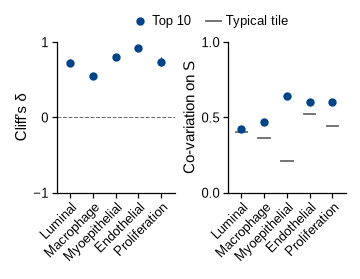

In [6]:
E_W, E_H = 61.0, 46.0


def panel_e(P):
    g = pd.concat([pd.read_csv(RES / f"seed{s}" / "gene_lists.csv").assign(seed=s) for s in SEEDS])
    t = g[g["query"] == "T"]
    order = list(SIG_LABELS)
    m = t.groupby("list").mean(numeric_only=True).loc[order]
    s = t.groupby("list").std(numeric_only=True).loc[order]
    x = np.arange(len(order))
    labels = [SIG_LABELS[n] for n in order]

    ax = box(P, 2, 4, 29, 40, left=8.0, bottom=13.0, right=1.0, top=1.5)
    ax.axhline(0, color=ps.MUTED, lw=0.5, ls="--", zorder=1)
    ax.errorbar(x, m.delta, yerr=s.delta, fmt="o", ms=3, color=NAIVE, elinewidth=0.6, capsize=0, zorder=2)
    ax.set_ylim(-1, 1)
    ax.set_yticks([-1, 0, 1])
    ax.set_ylabel("Cliff's δ")

    bx = box(P, 31, 4, 29, 40, left=8.0, bottom=13.0, right=1.0, top=1.5)
    for i in x:
        bx.plot([i - 0.25, i + 0.25], [m.cov_all.iloc[i]] * 2, color=ps.MUTED, lw=0.9, zorder=1)
    bx.errorbar(x, m.cov_top, yerr=s.cov_top, fmt="o", ms=3, color=NAIVE, elinewidth=0.6, capsize=0, zorder=2)
    bx.set_ylim(0, 1)
    bx.set_yticks([0, 0.5, 1])
    bx.set_ylabel("Co-variation on S")
    for a in (ax, bx):
        a.set_xticks(x)
        a.set_xticklabels(labels, rotation=45, ha="right", rotation_mode="anchor")
        a.set_xlim(-0.6, len(order) - 0.4)
    legend(P, 16, 0, 40, 4, [Line2D([], [], ls="", marker="o", ms=3, color=NAIVE, label="Top 10"),
                               Line2D([], [], color=ps.MUTED, lw=0.9, label="Typical tile")], ncol=2)


fig = ps.panel(E_W, E_H)
panel_e(At(fig))
ps.save_panel(fig, FIG, "E")

## The figure

figures/fig6_breast/fig6_breast.pdf/.png: 180 x 178 mm, 1.9 / 4.4 MB


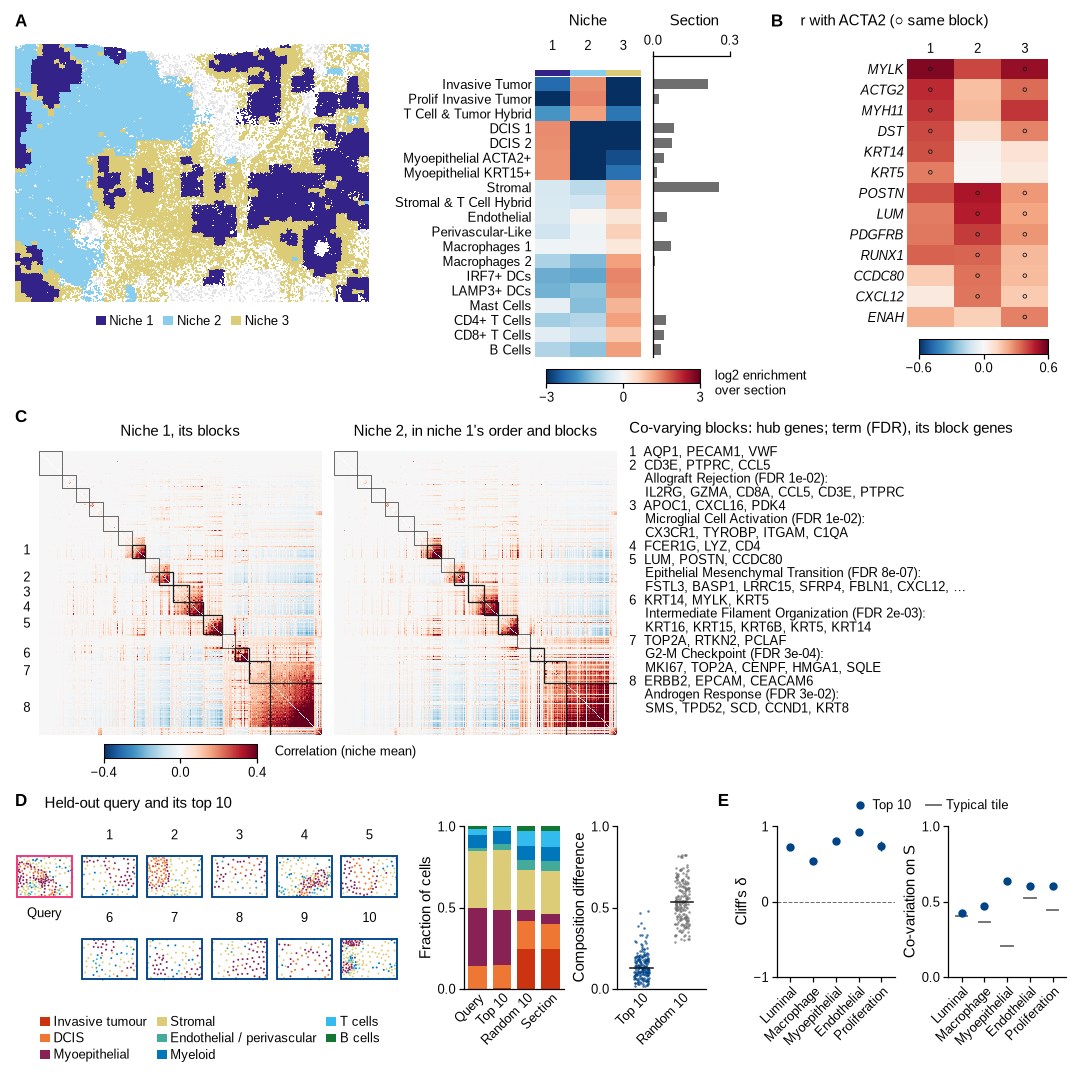

In [7]:
page = ps.page(180, 178)
panel_a(At(ps.place(page, "A", 0, 0, A_W, A_H)))
panel_b(At(ps.place(page, "B", 128, 0, B_W, B_H)))
panel_c(At(ps.place(page, "C", 0, 67, C_W, C_H)))
panel_d(At(ps.place(page, "D", 0, 132, D_W, D_H)))
panel_e(At(ps.place(page, "E", 119, 132, E_W, E_H)))
ps.save_figure(page, FIG)